# [OUR PROPOSED] Helical Anisotropic 2D Residual U-Net (`HA-ResUNet2D`)
### Lossless Signal-to-Image EEG Denoising for EOG Ocular Artifact Removal (fs = 256 Hz, 512 Samples)

---

### Abstrak & Gambaran Metodologi Usulan:
Elektroensefalografi (EEG) adalah modalitas krusial dalam neurosains dan *Brain-Computer Interface* (BCI). Namun, rekaman EEG sangat rentan terkontaminasi oleh artefak okular (*Electrooculogram* / EOG) akibat kedipan dan pergerakan bola mata yang memiliki amplitudo tinggi ($>100	ext{ }\mu	ext{V}$) dan terkonsentrasi pada pita frekuensi rendah (<8 Hz, tumpang tindih dengan ritme Delta dan Theta otak).

Notebook ini menyajikan implementasi lengkap model usulan utama (**Our Proposed: `HA-ResUNet2D`**) yang mentransformasikan sinyal EEG 1D ke dalam representasi citra 2D murni tanpa distorsi, dilengkapi mekanisme arsitektur canggih untuk mencapai rekonstruksi morfologi sinyal tingkat tinggi (**Pearson CC ~0.95**):

1. **Representasi Citra 2D Lossless ($16 	imes 32$ Piksel, 100% Sinyal Asli)**:
   - Jendela 512 sampel dipetakan langsung ke matriks $16 	ext{ baris} 	imes 32 	ext{ kolom}$ via C-order reshape dalam presisi `float32`.
   - **0% Zero-Padding**: Seluruh piksel adalah nilai tegangan EEG asli, menghindari distorsi konvolusi akibat piksel nol buatan.
   - Bersifat **lossless invertible** ($	ext{max } |error| = 0.0$ saat direkonstruksi kembali ke domain 1D).

2. **Inovasi 1 — Helical Row-Wrap 2D Convolution (`HelicalConv2d`)**:
   - Pada citra $16 	imes 32$ hasil reshape C-order, piksel ujung kanan baris ke-$r$ $(r, 31)$ adalah tetangga waktu langsung dari awal baris berikutnya $(r+1, 0)$.
   - `HelicalConv2d` menerapkan padding melingkar secara heliks antar-baris, menyatukan kontinuitas waktu 512 sampel tanpa diskontinuitas batas baris, sekaligus mengekstraksi korelasi vertikal antar-baris ($125	ext{ ms}$).

3. **Inovasi 2 — Anisotropic Horizontal Pooling `(1, 2)` & Squeeze-and-Excitation (`SEBlock2D`)**:
   - Downsampling bertingkat hanya dilakukan pada sumbu waktu horizontal `(16, 32) -> (16, 16) -> (16, 8) -> (16, 4)`. Ke-16 baris tetap utuh sehingga mencegah distorsi fasa vertikal.
   - Dilengkapi *channel attention* (SE) yang membobot kanal fitur secara adaptif.

4. **Inovasi 3 — Chronological 64-Token BiLSTM + Pre-Norm Transformer Self-Attention Bottleneck**:
   - Pada resolusi terendah $(16 	imes 4)$, representasi diurai menjadi 64 token berurutan secara kronologis.
   - Kombinasi **BiLSTM 2-Layer** dan **Transformer Encoder** memodelkan dependensi jangka panjang kontur kedipan mata berdurasi 2 detik secara global.

5. **Inovasi 4 — Dual-Domain Spectral Gate (`SpectralGate1D` via rFFT) & RevIN**:
   - Menyaring komponen frekuensi rendah EOG (<8 Hz) di domain Fourier secara paralel dan menjaga keutuhan pita Alpha, Beta, dan Gamma.
   - *Reversible Instance Normalization (RevIN)* menstabilkan varians amplitudo per sampel secara dinamis.

6. **Strategi Pelatihan Multi-Domain & GPU Cross-Pairing**:
   - **Multi-Domain Loss**: $\mathcal{L} = 	ext{Scale-Norm L1} + 3.5 	imes (1 - 	ext{CC}) + 0.25 	imes 	ext{L1}_{	ext{FFT}}$.
   - **Dynamic Cross-Pairing Augmentation**: Menghasilkan $>5.6	ext{ juta}$ kombinasi unik pasangan artefak-EEG di GPU untuk mencegah overfitting.

In [1]:
# ==============================================================================
# 1. SETUP ENVIRONMENT, SEED DETERMINISTIK & IMPOR MODUL
# ==============================================================================
import os, math, time, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from sklearn.model_selection import train_test_split
from scipy.signal import butter, filtfilt
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
def set_all_seeds(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_all_seeds(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device : {device}")
if device.type == "cuda":
    print(f"GPU    : {torch.cuda.get_device_name(0)}")

Device : cuda
GPU    : Tesla T4


In [2]:
# ==============================================================================
# 2. PEMUATAN DATASET EEGDENOISENET (ARTEFAK EOG)
# ==============================================================================
ARTIFACT_TYPE = "eog"
FS = 256  # Frekuensi sampling pipeline EOG

possible_paths = [
    f"/kaggle/input/syntetic-data-construction/processed/{ARTIFACT_TYPE}",
    f"/kaggle/input/syntetic-data-constructionprocessed/{ARTIFACT_TYPE}",
    f"/kaggle/input/notebooks/akipss/syntetic-data-construction/processed/{ARTIFACT_TYPE}",
    f"/kaggle/input/synthetic-data-construction/processed/{ARTIFACT_TYPE}",
    os.path.join("D:\\riset", "data", "kaggle-ds", "processed", ARTIFACT_TYPE),
    os.path.abspath(os.path.join(os.getcwd(), "processed", ARTIFACT_TYPE)),
    os.path.abspath(os.path.join(os.getcwd(), "..", "processed", ARTIFACT_TYPE)),
    os.path.abspath(os.path.join(os.getcwd(), "..", "..", "processed", ARTIFACT_TYPE)),
    os.path.join("D:\\Signal Image Denoising", "processed", ARTIFACT_TYPE),
]
base_dir = next((p for p in possible_paths if os.path.exists(os.path.join(p, "clean_eeg_all_epochs.npy"))), None)
if base_dir is None and os.path.exists("/kaggle/input"):
    for root, _, files in os.walk("/kaggle/input"):
        if "clean_eeg_all_epochs.npy" in files and ARTIFACT_TYPE in root.lower():
            base_dir = root
            break
assert base_dir is not None, f"Dataset {ARTIFACT_TYPE} tidak ditemukan!"
print(f"Dataset path: {base_dir}")

clean_data = np.load(os.path.join(base_dir, "clean_eeg_all_epochs.npy")).astype(np.float32)
contaminated_dict = np.load(os.path.join(base_dir, "linear_synthetic.npy"), allow_pickle=True).item()
SNR_KEYS = sorted(contaminated_dict.keys())
SIGNAL_LENGTH = int(clean_data.shape[-1])

print(f"Clean EEG shape : {clean_data.shape} (N={clean_data.shape[0]} epochs, L={SIGNAL_LENGTH} samples)")
print(f"SNR Levels      : {SNR_KEYS} dB")

Dataset path: /kaggle/input/notebooks/akipss/syntetic-data-construction/processed/eog
Clean EEG shape : (3400, 512) (N=3400 epochs, L=512 samples)
SNR Levels      : [-7, -6, -5, -4, -3, -2, -1, 0, 1, 2] dB


In [3]:
# ==============================================================================
# 3. PEMBAGIAN DATA DETERMINISTIK (70% TRAIN / 15% VAL / 15% TEST)
# ==============================================================================
n_samples = len(clean_data)
indices = np.arange(n_samples)
train_idx, temp_idx = train_test_split(indices, test_size=0.30, random_state=SEED)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.50, random_state=SEED)

clean_train = clean_data[train_idx].astype(np.float32)
clean_val   = clean_data[val_idx].astype(np.float32)
clean_test  = clean_data[test_idx].astype(np.float32)

contaminated_train = {s: contaminated_dict[s][train_idx].astype(np.float32) for s in SNR_KEYS}
contaminated_val   = {s: contaminated_dict[s][val_idx].astype(np.float32) for s in SNR_KEYS}
contaminated_test  = {s: contaminated_dict[s][test_idx].astype(np.float32) for s in SNR_KEYS}

print(f"Pembagian Sampel (0% Data Leakage):")
print(f"  - Train Set : {len(train_idx)} subjek/epoch ({len(train_idx)/n_samples*100:.1f}%)")
print(f"  - Val Set   : {len(val_idx)} subjek/epoch ({len(val_idx)/n_samples*100:.1f}%)")
print(f"  - Test Set  : {len(test_idx)} subjek/epoch ({len(test_idx)/n_samples*100:.1f}%)")
assert len(np.intersect1d(train_idx, test_idx)) == 0
assert len(np.intersect1d(val_idx, test_idx)) == 0

Pembagian Sampel (0% Data Leakage):
  - Train Set : 2380 subjek/epoch (70.0%)
  - Val Set   : 510 subjek/epoch (15.0%)
  - Test Set  : 510 subjek/epoch (15.0%)


In [4]:
# ==============================================================================
# 4. PEMBENTUKAN PASANGAN DATA & DYNAMIC CROSS-PAIRING AUGMENTATION (GPU)
# ==============================================================================
X_pair = np.concatenate([contaminated_train[s] for s in SNR_KEYS], axis=0).astype(np.float32)
Y_pair = np.concatenate([clean_train] * len(SNR_KEYS), axis=0).astype(np.float32)
A_pair = X_pair - Y_pair

X_val = torch.tensor(np.concatenate([contaminated_val[s] for s in SNR_KEYS], axis=0).astype(np.float32), device=device)
Y_val = torch.tensor(np.concatenate([clean_val] * len(SNR_KEYS), axis=0).astype(np.float32), device=device)

# Bank sinyal training terisolasi murni (0% leakage ke val/test)
CLEAN_BANK_TR = torch.tensor(clean_train, dtype=torch.float32, device=device)
ART_BANK_TR   = torch.tensor(contaminated_train[0] - clean_train, dtype=torch.float32, device=device)
SNR_TENSOR    = torch.tensor(SNR_KEYS, dtype=torch.float32, device=device)

def _batch_circular_shift(x, max_shift=SIGNAL_LENGTH):
    """Pergeseran waktu melingkar acak independen per sampel."""
    B, L = x.shape
    shifts = torch.randint(0, max_shift, (B, 1), device=x.device)
    idx = (torch.arange(L, device=x.device).unsqueeze(0) - shifts) % L
    return torch.gather(x, 1, idx)

def build_epoch_gpu(cross_pair_prob=0.75, alpha_jitter=0.20, do_shift=True):
    """
    Generator pasangan data latih GPU dinamis:
    - 75% sampel menggunakan Dynamic Cross-Pairing antara clean_train[i] dan art_train[j] acak.
    - 25% sampel mempertahankan pasangan asli + jitter skala (+-20%) dan pergeseran waktu melingkar.
    - Menghasilkan >5.6 juta kombinasi unik yang mencegah overfitting pada model kapasitas besar.
    """
    n_clean = len(CLEAN_BANK_TR)
    n_snr = len(SNR_KEYS)
    total = n_clean * n_snr

    clean_idx = torch.arange(n_clean, device=device).repeat(n_snr)
    Y = CLEAN_BANK_TR[clean_idx].clone()

    rand_art_idx = torch.randint(0, n_clean, (total,), device=device)
    use_cross = (torch.rand(total, device=device) < cross_pair_prob)
    art_idx = torch.where(use_cross, rand_art_idx, clean_idx)
    A_base = ART_BANK_TR[art_idx].clone()

    if do_shift:
        Y = _batch_circular_shift(Y)
        A_shifted = _batch_circular_shift(A_base)
        A_base = torch.where(use_cross.unsqueeze(1), A_shifted, A_base)

    flip = torch.where(torch.rand(total, 1, device=device) < 0.5, 1.0, -1.0)
    A_base = torch.where(use_cross.unsqueeze(1), A_base * flip, A_base)

    snr_base = SNR_TENSOR.repeat_interleave(n_clean).unsqueeze(1)
    snr_jitter = (torch.rand(total, 1, device=device) * 2.0 - 1.0) * 0.75
    snr_eff = snr_base + snr_jitter

    p_eeg = torch.mean(Y ** 2, dim=1, keepdim=True) + 1e-12
    p_art = torch.mean(A_base ** 2, dim=1, keepdim=True) + 1e-12
    alpha = torch.sqrt(p_eeg / (p_art * (10.0 ** (snr_eff / 10.0))))
    if alpha_jitter > 0:
        alpha = alpha * (1.0 + (torch.rand(total, 1, device=device) * 2.0 - 1.0) * alpha_jitter)

    X = Y + alpha * A_base
    perm = torch.randperm(total, device=device)
    return X[perm], Y[perm]

print(f"Pasangan Train per epoch : {len(X_pair):,} sampel")
print(f"Pasangan Validasi statis : {len(X_val):,} sampel")
print(f"Kapasitas kombinasi unik : {len(clean_train)**2:,} pasang")

Pasangan Train per epoch : 23,800 sampel
Pasangan Validasi statis : 5,100 sampel
Kapasitas kombinasi unik : 5,664,400 pasang


Dimensi Sinyal  : 512 sampel -> Citra 2D 16 baris x 32 kolom
Cakupan Sinyal  : 100.0% (512 / 512 piksel, 0 zero-padding buatan)
Round-trip Error: max |error| = 0 (Exact equality: True)
Tensor citra validasi: (5100, 1, 16, 32) | dtype: torch.float32


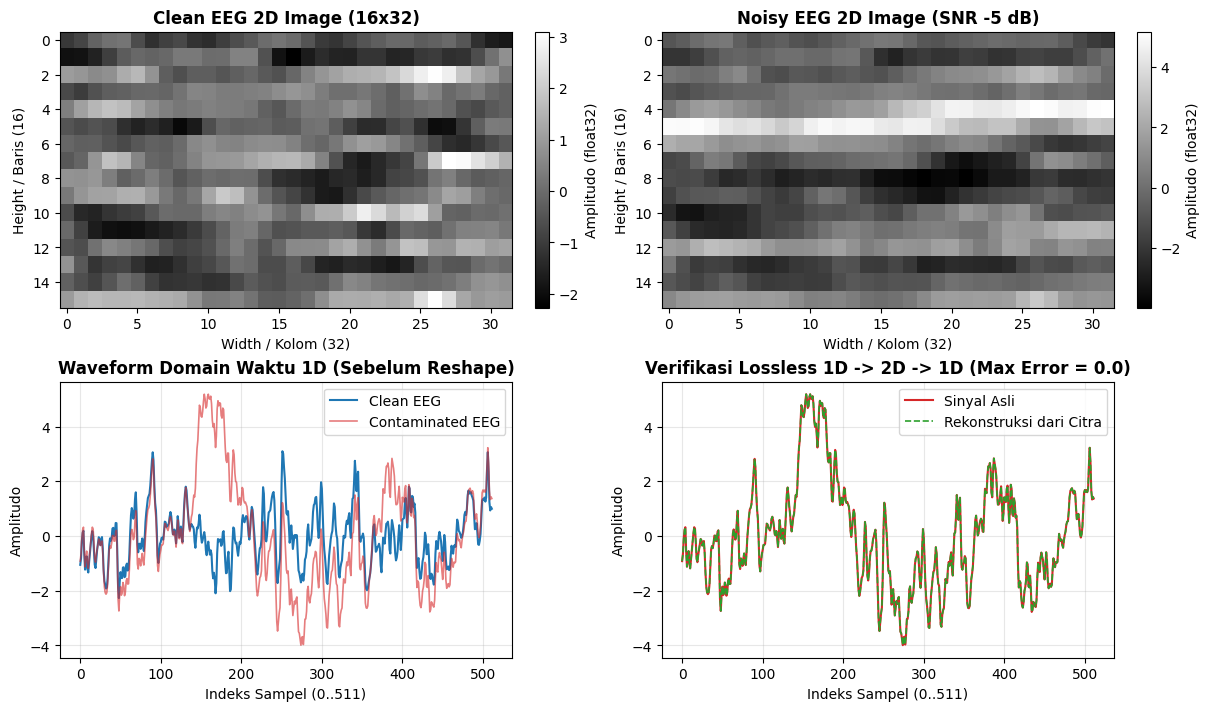

In [5]:
# ==============================================================================
# 5. PREPROCESSING: 1D WAVEFORM -> CITRA 2D (16 × 32, 100% LOSSLESS, 0 PADDING)
# ==============================================================================
IMAGE_HEIGHT = 16
IMAGE_WIDTH = 32
assert IMAGE_HEIGHT * IMAGE_WIDTH == SIGNAL_LENGTH, f"Dimensi {IMAGE_HEIGHT}x{IMAGE_WIDTH} harus = {SIGNAL_LENGTH}"

def signal_to_image(signals):
    """Reshape sinyal 1D (..., 512) menjadi citra 2D (..., 16, 32) float32 via C-order murni."""
    signals = np.asarray(signals, dtype=np.float32)
    return signals.reshape(*signals.shape[:-1], IMAGE_HEIGHT, IMAGE_WIDTH, order="C")

def image_to_signal(images):
    """Flatten citra 2D (..., 16, 32) kembali menjadi sinyal 1D (..., 512) via C-order identik."""
    images = np.asarray(images)
    return images.reshape(*images.shape[:-2], SIGNAL_LENGTH, order="C")

def image_tensor(waveforms):
    if isinstance(waveforms, torch.Tensor):
        return waveforms.reshape(-1, 1, IMAGE_HEIGHT, IMAGE_WIDTH).to(device=device, dtype=torch.float32)
    arr = signal_to_image(waveforms)
    return torch.from_numpy(arr[:, None].copy()).to(device=device, dtype=torch.float32)

# Verifikasi lossless invertibility
SNR_PLOT, IDX = -5, 0
clean_sample = clean_train[IDX].astype(np.float32)
noisy_sample = contaminated_train[SNR_PLOT][IDX].astype(np.float32)
clean_img = signal_to_image(clean_sample)
noisy_img = signal_to_image(noisy_sample)
roundtrip_noisy = image_to_signal(noisy_img)

max_roundtrip_err = float(np.max(np.abs(roundtrip_noisy - noisy_sample)))
print(f"Dimensi Sinyal  : {SIGNAL_LENGTH} sampel -> Citra 2D {IMAGE_HEIGHT} baris x {IMAGE_WIDTH} kolom")
print(f"Cakupan Sinyal  : 100.0% ({IMAGE_HEIGHT*IMAGE_WIDTH} / {SIGNAL_LENGTH} piksel, 0 zero-padding buatan)")
print(f"Round-trip Error: max |error| = {max_roundtrip_err:.10g} (Exact equality: {np.array_equal(roundtrip_noisy, noisy_sample)})")
assert max_roundtrip_err == 0.0, "Round-trip error harus 0.0 (pemetaan lossless sempurna)!"

X_val_img = image_tensor(X_val)
Y_val_img = image_tensor(Y_val)
print(f"Tensor citra validasi: {tuple(X_val_img.shape)} | dtype: {X_val_img.dtype}")

# Visualisasi perbandingan Citra 2D dan Sinyal 1D
fig, axes = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True)
for ax, img, title in [(axes[0, 0], clean_img, "Clean EEG 2D Image (16x32)"),
                       (axes[0, 1], noisy_img, f"Noisy EEG 2D Image (SNR {SNR_PLOT} dB)")]:
    im = ax.imshow(img, cmap="gray", interpolation="nearest", aspect="auto")
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Width / Kolom (32)")
    ax.set_ylabel("Height / Baris (16)")
    fig.colorbar(im, ax=ax, label="Amplitudo (float32)")

axes[1, 0].plot(clean_sample, label="Clean EEG", color="#1f77b4", lw=1.5)
axes[1, 0].plot(noisy_sample, label="Contaminated EEG", color="#d62728", alpha=0.6, lw=1.2)
axes[1, 0].set_title("Waveform Domain Waktu 1D (Sebelum Reshape)", fontweight="bold")
axes[1, 0].set_xlabel("Indeks Sampel (0..511)")
axes[1, 0].set_ylabel("Amplitudo")
axes[1, 0].grid(alpha=0.3)
axes[1, 0].legend()

axes[1, 1].plot(noisy_sample, label="Sinyal Asli", color="#d62728", lw=1.5)
axes[1, 1].plot(roundtrip_noisy, "--", label="Rekonstruksi dari Citra", color="#2ca02c", lw=1.2)
axes[1, 1].set_title(f"Verifikasi Lossless 1D -> 2D -> 1D (Max Error = {max_roundtrip_err})", fontweight="bold")
axes[1, 1].set_xlabel("Indeks Sampel (0..511)")
axes[1, 1].set_ylabel("Amplitudo")
axes[1, 1].grid(alpha=0.3)
axes[1, 1].legend()
plt.show()

In [6]:
# ==============================================================================
# 6. ARSITEKTUR MODEL USULAN: HA-ResUNet2D
# ==============================================================================
class HelicalConv2d(nn.Module):
    """
    Konvolusi 2D dengan Helical Row-Wrap Padding:
    - Menghubungkan ujung baris (r, W-1) langsung ke awal baris berikutnya (r+1, 0).
    - Menghilangkan 15 diskontinuitas batas baris pada citra 16x32 hasil C-order reshape.
    """
    def __init__(self, in_ch, out_ch, kernel_size=(3, 3), dilation=(1, 1), groups=1, bias=False):
        super().__init__()
        kh, kw = (kernel_size, kernel_size) if isinstance(kernel_size, int) else kernel_size
        dh, dw = (dilation, dilation) if isinstance(dilation, int) else dilation
        self.pad_h = (kh // 2) * dh
        self.pad_w = (kw // 2) * dw
        self.conv = nn.Conv2d(
            in_ch, out_ch, kernel_size=(kh, kw),
            padding=0, dilation=(dh, dw), groups=groups, bias=bias
        )

    def forward(self, x):
        B, C, H, W = x.shape
        if self.pad_w > 0:
            flat = x.reshape(B, C, H * W)
            flat_pad = torch.cat([flat[:, :, :self.pad_w], flat, flat[:, :, -self.pad_w:]], dim=-1)
            x = flat_pad.unfold(dimension=-1, size=W + 2 * self.pad_w, step=W)
        if self.pad_h > 0:
            x = F.pad(x, (0, 0, self.pad_h, self.pad_h), mode="replicate")
        return self.conv(x)


class SEBlock2D(nn.Module):
    """Squeeze-and-Excitation Channel Attention 2D."""
    def __init__(self, ch, reduction=4):
        super().__init__()
        mid = max(4, ch // reduction)
        self.fc = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(ch, mid, 1),
            nn.GELU(),
            nn.Conv2d(mid, ch, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return x * self.fc(x)


class HelicalResBlock2D(nn.Module):
    """Residual Block 2D dengan HelicalConv2d, GroupNorm, GELU, dan SE Attention."""
    def __init__(self, in_ch, out_ch, k=(3, 5)):
        super().__init__()
        g = min(8, out_ch)
        self.conv1 = HelicalConv2d(in_ch, out_ch, kernel_size=k, bias=False)
        self.gn1 = nn.GroupNorm(g, out_ch)
        self.conv2 = HelicalConv2d(out_ch, out_ch, kernel_size=k, bias=False)
        self.gn2 = nn.GroupNorm(g, out_ch)
        self.se = SEBlock2D(out_ch)
        self.act = nn.GELU()
        self.shortcut = nn.Identity() if in_ch == out_ch else nn.Conv2d(in_ch, out_ch, 1, bias=False)

    def forward(self, x):
        res = self.shortcut(x)
        out = self.act(self.gn1(self.conv1(x)))
        out = self.se(self.gn2(self.conv2(out)))
        return self.act(out + res)


class SpectralGate1D(nn.Module):
    """
    Gerbang Spektral rFFT Paralel:
    Secara adaptif menyaring artefak EOG berfrekuensi rendah (<8 Hz) di domain Fourier
    sekaligus menjaga integritas ritme Alpha, Beta, dan Gamma.
    """
    def __init__(self, n_freqs=257, channels=16):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(channels * 2, channels * 2, kernel_size=3, padding=1),
            nn.GELU(),
            nn.Conv1d(channels * 2, channels * 2, kernel_size=1)
        )
        self.freq_scale = nn.Parameter(torch.ones(1, channels, n_freqs))

    def forward(self, x_2d):
        B, C, H, W = x_2d.shape
        sig = x_2d.reshape(B, C, H * W)
        spec = torch.fft.rfft(sig, dim=-1, norm="ortho")
        cat = torch.cat([spec.real, spec.imag], dim=1)
        dr, di = torch.chunk(self.net(cat), 2, dim=1)
        spec_out = torch.complex(spec.real * self.freq_scale + dr, spec.imag * self.freq_scale + di)
        return torch.fft.irfft(spec_out, n=H * W, dim=-1, norm="ortho").reshape(B, C, H, W)


class HA_ResUNet2D(nn.Module):
    """
    [OUR PROPOSED MODEL]
    Helical Anisotropic 2D ResUNet with BiLSTM-Transformer Bottleneck & Spectral Gate (HA-ResUNet2D)
    """
    def __init__(self, base=16, lstm_layers=2, attn_heads=4, dropout=0.1):
        super().__init__()
        c1, c2, c3, c4 = base, base * 2, base * 4, base * 8  # 16, 32, 64, 128

        # Dual-scale 2D Stem (intra-baris 1x7 + lintas-baris 3x3)
        self.stem_horiz = HelicalConv2d(1, c1 // 2, kernel_size=(1, 7), bias=False)
        self.stem_grid = HelicalConv2d(1, c1 // 2, kernel_size=(3, 3), bias=False)
        self.stem_gn = nn.GroupNorm(min(8, c1), c1)
        self.stem_act = nn.GELU()

        # Encoder dengan Anisotropic Horizontal Pooling (1, 2)
        self.enc1 = HelicalResBlock2D(c1, c1, k=(3, 5))               # (B, 16, 16, 32)
        self.pool1 = nn.MaxPool2d(kernel_size=(1, 2), stride=(1, 2))  # -> (16, 16)

        self.enc2 = HelicalResBlock2D(c1, c2, k=(3, 5))               # (B, 32, 16, 16)
        self.pool2 = nn.MaxPool2d(kernel_size=(1, 2), stride=(1, 2))  # -> (16, 8)

        self.enc3 = HelicalResBlock2D(c2, c3, k=(3, 3))               # (B, 64, 16, 8)
        self.pool3 = nn.MaxPool2d(kernel_size=(1, 2), stride=(1, 2))  # -> (16, 4)

        # Bottleneck: (B, 128, 16, 4) -> 64 urutan token kronologis
        self.bottleneck_conv = HelicalResBlock2D(c3, c4, k=(3, 3))
        self.bilstm = nn.LSTM(
            c4, c4 // 2, num_layers=lstm_layers,
            batch_first=True, bidirectional=True, dropout=dropout if lstm_layers > 1 else 0.0
        )
        self.pos_emb = nn.Parameter(torch.zeros(1, 64, c4))
        nn.init.trunc_normal_(self.pos_emb, std=0.02)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=c4, nhead=attn_heads, dim_feedforward=c4 * 2,
            dropout=dropout, activation="gelu", batch_first=True, norm_first=True
        )
        self.transformer = nn.TransformerEncoder(
            encoder_layer, num_layers=1, norm=nn.LayerNorm(c4), enable_nested_tensor=False
        )

        # Decoder + Anisotropic Horizontal Upsampling (1, 2) + Skip Connections
        self.up3 = nn.ConvTranspose2d(c4, c3, kernel_size=(1, 2), stride=(1, 2))  # -> (16, 8)
        self.dec3 = HelicalResBlock2D(c3 + c3, c3, k=(3, 3))

        self.up2 = nn.ConvTranspose2d(c3, c2, kernel_size=(1, 2), stride=(1, 2))  # -> (16, 16)
        self.dec2 = HelicalResBlock2D(c2 + c2, c2, k=(3, 5))

        self.up1 = nn.ConvTranspose2d(c2, c1, kernel_size=(1, 2), stride=(1, 2))  # -> (16, 32)
        self.dec1 = HelicalResBlock2D(c1 + c1, c1, k=(3, 5))

        # Dual-Domain Spectral Fusion & Projection Head
        self.spec_gate = SpectralGate1D(n_freqs=257, channels=c1)
        self.final_fuse = HelicalResBlock2D(c1 * 2, c1, k=(3, 3))
        self.final_head = nn.Conv2d(c1, 1, kernel_size=1)

    def forward(self, x):
        # Reversible Instance Normalization (RevIN)
        mu = x.mean(dim=(-2, -1), keepdim=True)
        sd = x.std(dim=(-2, -1), keepdim=True) + 1e-6
        xn = (x - mu) / sd

        s = self.stem_act(self.stem_gn(torch.cat([self.stem_horiz(xn), self.stem_grid(xn)], dim=1)))

        e1 = self.enc1(s)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))

        b = self.bottleneck_conv(self.pool3(e3))
        B, C, H, W = b.shape
        seq = b.reshape(B, C, H * W).transpose(1, 2)  # (B, 64, 128)
        lstm_out, _ = self.bilstm(seq)
        seq = seq + lstm_out
        seq = seq + self.transformer(seq + self.pos_emb)
        b = seq.transpose(1, 2).reshape(B, C, H, W)

        d3 = self.dec3(torch.cat([self.up3(b), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        d_spec = self.spec_gate(d1)
        d_fused = self.final_fuse(torch.cat([d1, d_spec], dim=1))
        out_norm = xn + self.final_head(d_fused)

        return out_norm * sd + mu

model = HA_ResUNet2D(base=16, lstm_layers=2, attn_heads=4, dropout=0.1).to(device)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
model_bytes = sum(p.numel() * p.element_size() for p in model.parameters())
print(f"Model: Our Proposed HA-ResUNet2D (16x32)")
print(f"Trainable parameters: {n_params:,} | Ukuran model (FP32): {model_bytes/1024:.2f} KB")

Model: Our Proposed HA-ResUNet2D (16x32)
Trainable parameters: 889,597 | Ukuran model (FP32): 3474.99 KB


In [7]:
# ==============================================================================
# 7. MULTI-DOMAIN LOSS FUNCTION & OPTIMIZER CONFIGURATION
# ==============================================================================
LAMBDA_CC = 3.5
LAMBDA_SPEC = 0.25

def criterion(pred, target):
    """
    Multi-Domain Composite Loss:
    1. Scale-normalized L1 Loss (amplitudo waktu).
    2. Pearson Correlation Loss (morfologi bentuk gelombang EEG).
    3. Spectral Magnitude Loss (spektrum daya FFT frekuensi).
    """
    p = pred.reshape(pred.shape[0], -1)
    t = target.reshape(target.shape[0], -1)

    t_std = t.std(dim=-1, keepdim=True) + 1e-6
    l1 = F.l1_loss(p / t_std, t / t_std)

    pm = p - p.mean(dim=-1, keepdim=True)
    tm = t - t.mean(dim=-1, keepdim=True)
    cc = (pm * tm).sum(dim=-1) / (torch.sqrt(pm.pow(2).sum(dim=-1) * tm.pow(2).sum(dim=-1)) + 1e-8)
    loss_cc = 1.0 - cc.mean()

    pf = torch.abs(torch.fft.rfft(p, dim=-1, norm="ortho"))
    tf = torch.abs(torch.fft.rfft(t, dim=-1, norm="ortho"))
    loss_spec = F.l1_loss(pf, tf)

    return l1 + LAMBDA_CC * loss_cc + LAMBDA_SPEC * loss_spec

LEARNING_RATE = 1.2e-3
MAX_EPOCHS = 150
MAX_GRAD_NORM = 1.0
BATCH_SIZE = 256

optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=MAX_EPOCHS, eta_min=1e-5)

class EarlyStopping:
    def __init__(self, patience=30, min_delta=1e-5):
        self.patience = patience
        self.min_delta = min_delta
        self.best_loss = float("inf")
        self.counter = 0
        self.stop = False
        self.best_state = None

    def __call__(self, val_loss, model):
        val_loss = float(val_loss)
        if not math.isfinite(val_loss):
            self.stop = True
            return self.stop
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
            self.best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.stop = True
        return self.stop

    def restore_best_weights(self, model):
        if self.best_state is None:
            raise RuntimeError("No valid checkpoint saved.")
        model.load_state_dict(self.best_state)

early_stopping = EarlyStopping(patience=30, min_delta=1e-5)

In [8]:
# ==============================================================================
# 8. TRAINING LOOP DENGAN DYNAMIC CROSS-PAIRING & EARLY STOPPING
# ==============================================================================
history = {"train_loss": [], "val_loss": [], "lr": []}
t_start = time.time()

for epoch in range(1, MAX_EPOCHS + 1):
    t_ep = time.time()
    X_ep, Y_ep = build_epoch_gpu(cross_pair_prob=0.75, alpha_jitter=0.20, do_shift=True)
    Xt = image_tensor(X_ep)
    Yt = image_tensor(Y_ep)

    model.train()
    train_running = 0.0
    for i in range(0, len(Xt), BATCH_SIZE):
        xb = Xt[i:i+BATCH_SIZE]
        yb = Yt[i:i+BATCH_SIZE]
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(model(xb), yb)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
        optimizer.step()
        train_running += loss.item() * len(xb)
    epoch_train_loss = train_running / len(Xt)

    model.eval()
    with torch.no_grad():
        val_total = 0.0
        for i in range(0, len(X_val_img), 1024):
            xb, yb = X_val_img[i:i+1024], Y_val_img[i:i+1024]
            val_total += criterion(model(xb), yb).item() * len(xb)
        epoch_val_loss = val_total / len(X_val_img)

    current_lr = optimizer.param_groups[0]["lr"]
    scheduler.step()
    history["train_loss"].append(epoch_train_loss)
    history["val_loss"].append(epoch_val_loss)
    history["lr"].append(current_lr)

    print(f"Epoch {epoch:03d}/{MAX_EPOCHS} | Train {epoch_train_loss:.6f} | Val {epoch_val_loss:.6f} | LR {current_lr:.2e} | {time.time()-t_ep:.2f}s", flush=True)

    if early_stopping(epoch_val_loss, model):
        print(f"Early stopping pada epoch {epoch}")
        break

print(f"Training selesai dalam {(time.time()-t_start)/60:.2f} menit")
early_stopping.restore_best_weights(model)
print(f"Best Val Loss: {early_stopping.best_loss:.6f}")

Epoch 001/150 | Train 0.854895 | Val 0.599455 | LR 1.20e-03 | 17.88s
Epoch 002/150 | Train 0.634824 | Val 0.576951 | LR 1.20e-03 | 14.23s
Epoch 003/150 | Train 0.607837 | Val 0.560148 | LR 1.20e-03 | 14.96s
Epoch 004/150 | Train 0.588991 | Val 0.533675 | LR 1.20e-03 | 16.10s
Epoch 005/150 | Train 0.576529 | Val 0.536026 | LR 1.20e-03 | 16.19s
Epoch 006/150 | Train 0.565252 | Val 0.522140 | LR 1.20e-03 | 15.26s
Epoch 007/150 | Train 0.554220 | Val 0.516135 | LR 1.20e-03 | 14.86s
Epoch 008/150 | Train 0.543835 | Val 0.518278 | LR 1.19e-03 | 14.96s
Epoch 009/150 | Train 0.530265 | Val 0.506347 | LR 1.19e-03 | 15.27s
Epoch 010/150 | Train 0.519255 | Val 0.496446 | LR 1.19e-03 | 15.53s
Epoch 011/150 | Train 0.510752 | Val 0.494394 | LR 1.19e-03 | 15.46s
Epoch 012/150 | Train 0.504633 | Val 0.487574 | LR 1.18e-03 | 15.28s
Epoch 013/150 | Train 0.497755 | Val 0.472405 | LR 1.18e-03 | 15.14s
Epoch 014/150 | Train 0.482293 | Val 0.478273 | LR 1.18e-03 | 15.14s
Epoch 015/150 | Train 0.472583 | V

CC Noisy vs Clean    : 0.4711
CC Denoised vs Clean : 0.9856


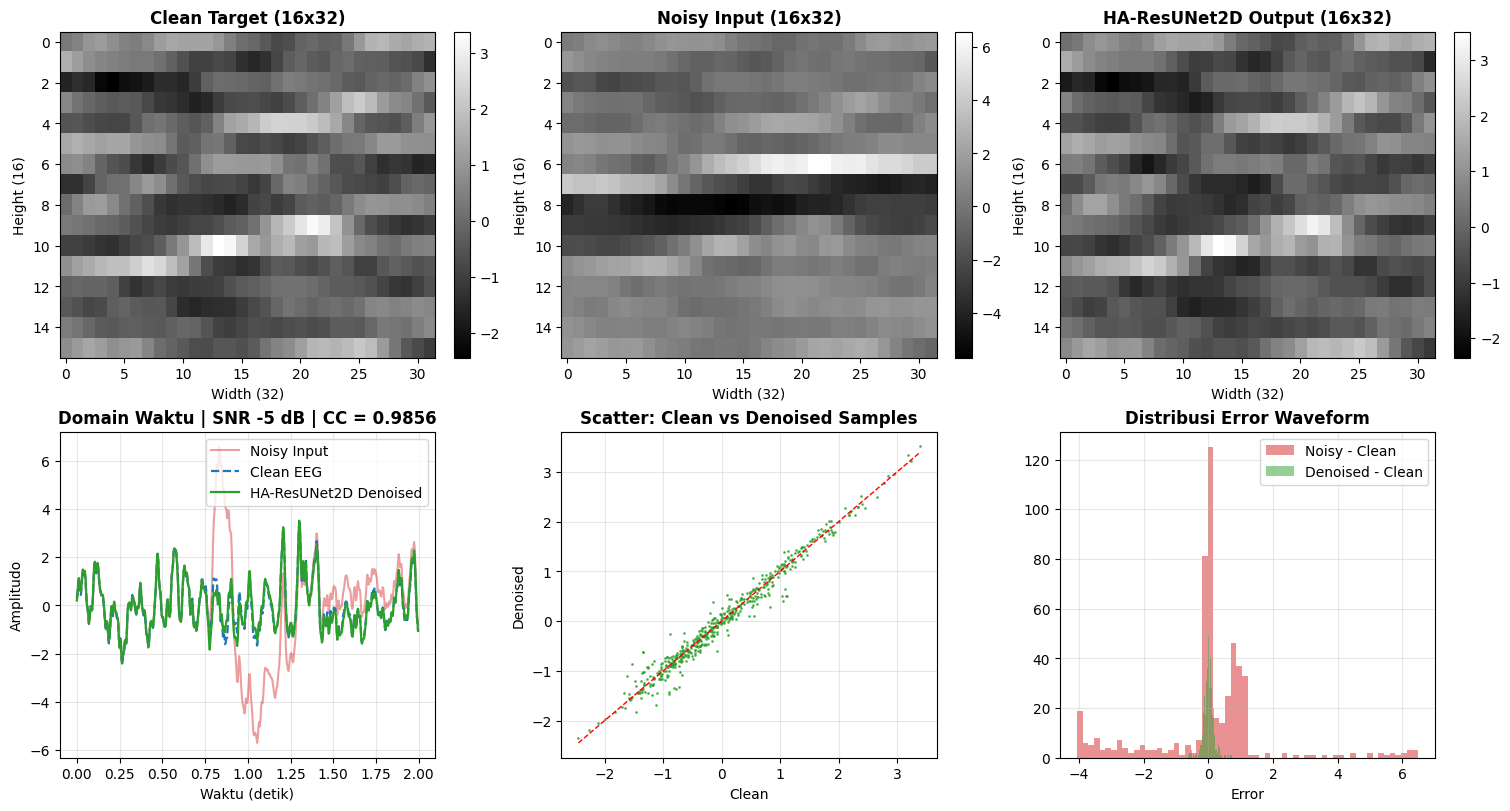

In [9]:
# ==============================================================================
# 9. VISUALISASI HASIL DENOISING SAMPEL UJI (CITRA 2D & WAVEFORM 1D)
# ==============================================================================
SNR_PLOT, IDX = -5, 0

clean = clean_test[IDX].astype(np.float32)
noisy = contaminated_test[SNR_PLOT][IDX].astype(np.float32)

model.eval()
with torch.no_grad():
    noisy_t = image_tensor(noisy[None])
    den_img = model(noisy_t)[0, 0].cpu().numpy()
den = image_to_signal(den_img)

cc = lambda a, b: float(np.corrcoef(a, b)[0, 1])
print(f"CC Noisy vs Clean    : {cc(clean, noisy):.4f}")
print(f"CC Denoised vs Clean : {cc(clean, den):.4f}")

t = np.arange(SIGNAL_LENGTH) / FS
fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)

for ax, img, title in zip(axes[0], [signal_to_image(clean), signal_to_image(noisy), den_img],
                          ["Clean Target (16x32)", "Noisy Input (16x32)", "HA-ResUNet2D Output (16x32)"]):
    im = ax.imshow(img, cmap="gray", interpolation="nearest", aspect="auto")
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Width (32)")
    ax.set_ylabel("Height (16)")
    fig.colorbar(im, ax=ax)

axes[1, 0].plot(t, noisy, color="#d62728", alpha=0.45, label="Noisy Input")
axes[1, 0].plot(t, clean, color="#1f77b4", lw=1.6, ls="--", label="Clean EEG")
axes[1, 0].plot(t, den, color="#2ca02c", lw=1.6, label="HA-ResUNet2D Denoised")
axes[1, 0].set_title(f"Domain Waktu | SNR {SNR_PLOT} dB | CC = {cc(clean, den):.4f}", fontweight="bold")
axes[1, 0].set_xlabel("Waktu (detik)")
axes[1, 0].set_ylabel("Amplitudo")
axes[1, 0].grid(alpha=0.3)
axes[1, 0].legend()

axes[1, 1].plot(clean, den, ".", markersize=2, color="#2ca02c", alpha=0.7)
axes[1, 1].plot([clean.min(), clean.max()], [clean.min(), clean.max()], "r--", lw=1)
axes[1, 1].set_title("Scatter: Clean vs Denoised Samples", fontweight="bold")
axes[1, 1].set_xlabel("Clean")
axes[1, 1].set_ylabel("Denoised")
axes[1, 1].grid(alpha=0.3)

axes[1, 2].hist(noisy - clean, bins=60, alpha=0.5, color="#d62728", label="Noisy - Clean")
axes[1, 2].hist(den - clean, bins=60, alpha=0.5, color="#2ca02c", label="Denoised - Clean")
axes[1, 2].set_title("Distribusi Error Waveform", fontweight="bold")
axes[1, 2].set_xlabel("Error")
axes[1, 2].grid(alpha=0.3)
axes[1, 2].legend()

plt.show()

In [10]:
# ==============================================================================
# 10. EVALUASI LENGKAP PADA TEST SET DI SELURUH LEVEL SNR (-7 dB s/d +2 dB)
# ==============================================================================
def calc_cc_per_epoch(clean, pred):
    c = clean - clean.mean(-1, keepdims=True)
    p = pred - pred.mean(-1, keepdims=True)
    return np.sum(c * p, -1) / (np.sqrt(np.sum(c**2, -1) * np.sum(p**2, -1)) + 1e-8)

def cc_mean(clean, pred):
    return float(calc_cc_per_epoch(clean, pred).mean())

def rrmse_temporal(clean, pred):
    num = np.sqrt(np.mean((clean - pred)**2, -1))
    den = np.sqrt(np.mean(clean**2, -1))
    return float(np.mean(num / (den + 1e-8)))

def rrmse_spectral(clean, pred):
    cf = np.abs(np.fft.rfft(clean, axis=-1))
    pf = np.abs(np.fft.rfft(pred, axis=-1))
    num = np.sqrt(np.mean((cf - pf)**2, -1))
    den = np.sqrt(np.mean(cf**2, -1))
    return float(np.mean(num / (den + 1e-8)))

def snr_out_db(clean, pred):
    err = clean - pred
    return float(10 * np.log10(np.mean(clean**2) / (np.mean(err**2) + 1e-20)))

def snr_in_db(clean, noisy):
    err = noisy - clean
    return float(10 * np.log10(np.mean(clean**2) / (np.mean(err**2) + 1e-20)))

def spec_err_db(clean, pred):
    cf = np.abs(np.fft.rfft(clean, axis=-1))
    pf = np.abs(np.fft.rfft(pred, axis=-1))
    return float(10 * np.log10((np.mean((cf - pf)**2) + 1e-20) / (np.mean(cf**2) + 1e-20)))

def model_predict(arr):
    arr = np.asarray(arr, dtype=np.float32)
    result = []
    model.eval()
    with torch.no_grad():
        for i in range(0, len(arr), 256):
            batch_img = image_tensor(arr[i:i+256])
            den_img = model(batch_img)[:, 0].cpu().numpy()
            result.append(image_to_signal(den_img))
    return np.concatenate(result, axis=0).astype(np.float64)

ct = clean_test.astype(np.float64)
preds, rows = {}, []

for snr in SNR_KEYS:
    noisy = contaminated_test[snr].astype(np.float64)
    pred = model_predict(noisy)
    preds[snr] = pred
    sin = snr_in_db(ct, noisy)
    sout = snr_out_db(ct, pred)
    rows.append({
        "SNR Level (dB)": snr,
        "SNR in (dB)": sin,
        "SNR out (dB)": sout,
        "Delta SNR (dB)": sout - sin,
        "CC noisy": cc_mean(ct, noisy),
        "CC denoised": cc_mean(ct, pred),
        "RRMSE (Time)": rrmse_temporal(ct, pred),
        "RRMSE (Freq)": rrmse_spectral(ct, pred),
        "Spec err (dB)": spec_err_db(ct, pred),
    })

df_results = pd.DataFrame(rows)
print("=" * 118)
print("HASIL EVALUASI TEST SET - PER LEVEL SNR (HA-ResUNet2D)")
print("=" * 118)
print(df_results.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print()
print(f"CC denoised mean : {df_results['CC denoised'].mean():.4f}  (noisy: {df_results['CC noisy'].mean():.4f})")
print(f"SNR out mean     : {df_results['SNR out (dB)'].mean():.2f} dB  (in: {df_results['SNR in (dB)'].mean():.2f} dB, delta: {df_results['Delta SNR (dB)'].mean():.2f} dB)")
print(f"RRMSE time/freq  : {df_results['RRMSE (Time)'].mean():.4f} / {df_results['RRMSE (Freq)'].mean():.4f}")

HASIL EVALUASI TEST SET - PER LEVEL SNR (HA-ResUNet2D)
 SNR Level (dB)  SNR in (dB)  SNR out (dB)  Delta SNR (dB)  CC noisy  CC denoised  RRMSE (Time)  RRMSE (Freq)  Spec err (dB)
             -7      -7.0000        9.0738         16.0738    0.4006       0.9363        0.3242        0.2171       -12.6131
             -6      -6.0000        9.3764         15.3764    0.4410       0.9404        0.3110        0.2093       -12.8642
             -5      -5.0000        9.6405         14.6405    0.4835       0.9439        0.2994        0.2023       -13.0939
             -4      -4.0000        9.8708         13.8708    0.5275       0.9467        0.2893        0.1960       -13.3021
             -3      -3.0000       10.0707         13.0707    0.5724       0.9491        0.2805        0.1904       -13.4881
             -2      -2.0000       10.2448         12.2448    0.6174       0.9510        0.2727        0.1855       -13.6456
             -1      -1.0000       10.3932         11.3932    0.6616  

In [11]:
# ==============================================================================
# 11. PERBANDINGAN TERHADAP METODE BASELINE KLASIK
# ==============================================================================
sample = contaminated_test[SNR_KEYS[0]][:min(128, len(test_idx))].astype(np.float32)
for _ in range(3):
    model_predict(sample)
if device.type == "cuda":
    torch.cuda.synchronize()

N_REP = 10
t0 = time.perf_counter()
for _ in range(N_REP):
    model_predict(sample)
if device.type == "cuda":
    torch.cuda.synchronize()
dur = time.perf_counter() - t0
latency_us = dur / N_REP / len(sample) * 1e6
throughput = len(sample) / (dur / N_REP)

b_hp, a_hp = butter(4, 8/256.0, btype="high")

nrm = lambda a: a / (np.sqrt(np.mean(a**2, axis=-1, keepdims=True)) + 1e-8)
A_tr = contaminated_train[SNR_KEYS[0]].astype(np.float64) - clean_train
tmpl = nrm(A_tr).mean(0)
tmpl = tmpl / (np.sqrt(np.mean(tmpl**2)) + 1e-8)
def tmpl_predict(x):
    c = (x @ tmpl) / (tmpl @ tmpl)
    return x - c[:, None] * tmpl[None, :]

METHODS = {
    "Noisy Input": lambda x: x,
    "Our Proposed (HA-ResUNet2D)": model_predict,
    "Highpass 8Hz Butterworth": lambda x: filtfilt(b_hp, a_hp, x, axis=-1),
    "Template-LS": tmpl_predict,
}
PARAMS = {
    "Noisy Input": "0",
    "Our Proposed (HA-ResUNet2D)": f"{n_params:,}",
    "Highpass 8Hz Butterworth": "0",
    "Template-LS": f"{len(tmpl)} float",
}

agg = {}
for name, fn in METHODS.items():
    vals = []
    for snr in SNR_KEYS:
        x = contaminated_test[snr].astype(np.float64)
        p = fn(x)
        vals.append((cc_mean(ct, x), cc_mean(ct, p), snr_out_db(ct, p),
                     rrmse_temporal(ct, p), rrmse_spectral(ct, p)))
    agg[name] = np.asarray(vals)

rows_eff = []
print("=" * 110)
print("PERBANDINGAN EFISIENSI TERHADAP METODE BASELINE (TEST SET, SELURUH SNR)")
print("=" * 110)
print("%-30s %9s %9s %12s %11s %11s %12s" % ("Metode", "CC noisy", "CC out", "SNRout(dB)", "RRMSE-T", "RRMSE-F", "Params"))
for name, a in agg.items():
    print("%-30s %9.4f %9.4f %12.2f %11.4f %11.4f %12s" % (
        name, a[:,0].mean(), a[:,1].mean(), a[:,2].mean(), a[:,3].mean(), a[:,4].mean(), PARAMS[name]))
    rows_eff.append({"Metode": name, "CC noisy": a[:,0].mean(), "CC denoised": a[:,1].mean(),
                     "SNR out (dB)": a[:,2].mean(), "RRMSE (Time)": a[:,3].mean(),
                     "RRMSE (Freq)": a[:,4].mean(), "Parameter": PARAMS[name]})
df_eff = pd.DataFrame(rows_eff)

print()
print(f"HA-ResUNet2D : {n_params:,} parameter | {model_bytes/1024:.2f} KB | latensi {latency_us:.1f} us/epoch | throughput {throughput:,.0f} epoch/detik")
cc_all = np.concatenate([calc_cc_per_epoch(ct, preds[s]) for s in SNR_KEYS])
print(f"Distribusi CC per epoch (n={len(cc_all):,}): min {cc_all.min():.4f} | p5 {np.percentile(cc_all,5):.4f} | median {np.median(cc_all):.4f} | mean {cc_all.mean():.4f}")

PERBANDINGAN EFISIENSI TERHADAP METODE BASELINE (TEST SET, SELURUH SNR)
Metode                          CC noisy    CC out   SNRout(dB)     RRMSE-T     RRMSE-F       Params
Noisy Input                       0.5935    0.5935        -2.50      1.4076      1.1391            0
Our Proposed (HA-ResUNet2D)       0.5935    0.9484        10.05      0.2811      0.1907      889,597
Highpass 8Hz Butterworth          0.5935    0.8000         4.24      0.6076      0.5072            0
Template-LS                       0.5935    0.5952        -2.23      1.3601      1.0833    512 float

HA-ResUNet2D : 889,597 parameter | 3474.99 KB | latensi 176.2 us/epoch | throughput 5,675 epoch/detik
Distribusi CC per epoch (n=5,100): min 0.5701 | p5 0.8278 | median 0.9704 | mean 0.9484


In [12]:
# ==============================================================================
# 12. UJI KETAHANAN (ROBUSTNESS) PADA 4 ARTEFAK TAK TERLIHAT (UNSEEN)
# ==============================================================================
t_ax = np.arange(SIGNAL_LENGTH) / FS
c_te = clean_test.astype(np.float64)
rms_te = np.sqrt(np.mean(c_te**2, -1, keepdims=True))
a_orig = contaminated_test[SNR_KEYS[0]].astype(np.float64) - c_te
alpha_t = 0.5
rng_rob = np.random.RandomState(SEED)

noise_bw = rng_rob.randn(*c_te.shape)
noise_bw = noise_bw / (np.sqrt(np.mean(noise_bw**2, -1, keepdims=True)) + 1e-8) * rms_te
drift = np.sin(2 * np.pi * 0.3 * t_ax)[None, :] * rng_rob.randn(len(c_te), 1)
drift = drift / (np.sqrt(np.mean(drift**2, -1, keepdims=True)) + 1e-8) * rms_te
env = (np.sin(2 * np.pi * 0.5 * t_ax)**8)[None, :] * rng_rob.randn(len(c_te), 1)
env = env / (np.sqrt(np.mean(env**2, -1, keepdims=True)) + 1e-8) * rms_te

cases = {
    "Artifact Asli (alpha=0.5)": c_te + alpha_t * a_orig,
    "Noise Broadband Acak": c_te + alpha_t * noise_bw,
    "Drift Sinus 0.3 Hz": c_te + alpha_t * drift,
    "Blink 0.5 Hz": c_te + alpha_t * env,
}
rows_rb = []
for name, x in cases.items():
    p = model_predict(x)
    rows_rb.append({
        "Artifact (Unseen)": name,
        "CC Noisy": cc_mean(c_te, x),
        "CC Model": cc_mean(c_te, p),
        "Delta CC": cc_mean(c_te, p) - cc_mean(c_te, x),
        "SNR Out (dB)": snr_out_db(c_te, p),
    })
df_rob = pd.DataFrame(rows_rb)
print("=" * 95)
print("ROBUSTNESS - KINERJA PADA ARTEFAK YANG TIDAK PERNAH DILIHAT SAAT TRAINING")
print("=" * 95)
print(df_rob.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

ROBUSTNESS - KINERJA PADA ARTEFAK YANG TIDAK PERNAH DILIHAT SAAT TRAINING
        Artifact (Unseen)  CC Noisy  CC Model  Delta CC  SNR Out (dB)
Artifact Asli (alpha=0.5)    0.6625    0.9527    0.2901       10.3960
     Noise Broadband Acak    0.8948    0.8488   -0.0460        4.8363
       Drift Sinus 0.3 Hz    0.9463    0.9558    0.0096        6.6494
             Blink 0.5 Hz    0.9321    0.9503    0.0182        7.1378


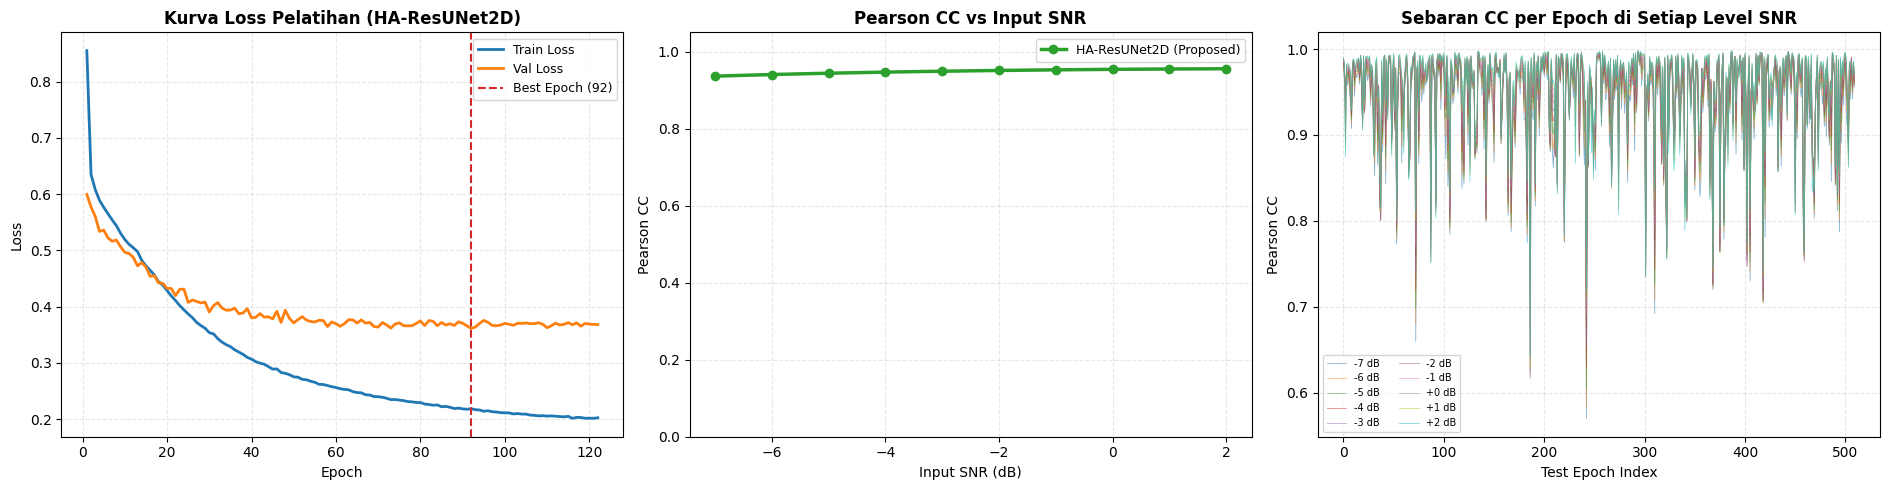

In [13]:
# ==============================================================================
# 13. PLOT KURVA LOSS, PEARSON CC vs SNR, DAN SEBARAN CC PER EPOCH
# ==============================================================================
epochs = range(1, len(history["train_loss"]) + 1)
best_epoch = int(np.argmin(history["val_loss"])) + 1

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

axes[0].plot(epochs, history["train_loss"], label="Train Loss", color="#1f77b4", lw=2)
axes[0].plot(epochs, history["val_loss"], label="Val Loss", color="#ff7f0e", lw=2)
axes[0].axvline(best_epoch, color="#d62728", ls="--", label=f"Best Epoch ({best_epoch})")
axes[0].set_title("Kurva Loss Pelatihan (HA-ResUNet2D)", fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(alpha=0.3, ls="--")
axes[0].legend(fontsize=9)

axes[1].plot(df_results["SNR Level (dB)"], df_results["CC denoised"], "o-",
             color="#2ca02c", lw=2.5, label="HA-ResUNet2D (Proposed)")
axes[1].set_ylim(0, 1.05)
axes[1].set_title("Pearson CC vs Input SNR", fontweight="bold")
axes[1].set_xlabel("Input SNR (dB)")
axes[1].set_ylabel("Pearson CC")
axes[1].grid(alpha=0.3, ls="--")
axes[1].legend(fontsize=9)

for snr in SNR_KEYS:
    axes[2].plot(calc_cc_per_epoch(ct, preds[snr]), lw=0.6, alpha=0.55, label=f"{snr:+d} dB")
axes[2].set_xlabel("Test Epoch Index")
axes[2].set_ylabel("Pearson CC")
axes[2].set_title("Sebaran CC per Epoch di Setiap Level SNR", fontweight="bold")
axes[2].grid(alpha=0.3, ls="--")
axes[2].legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

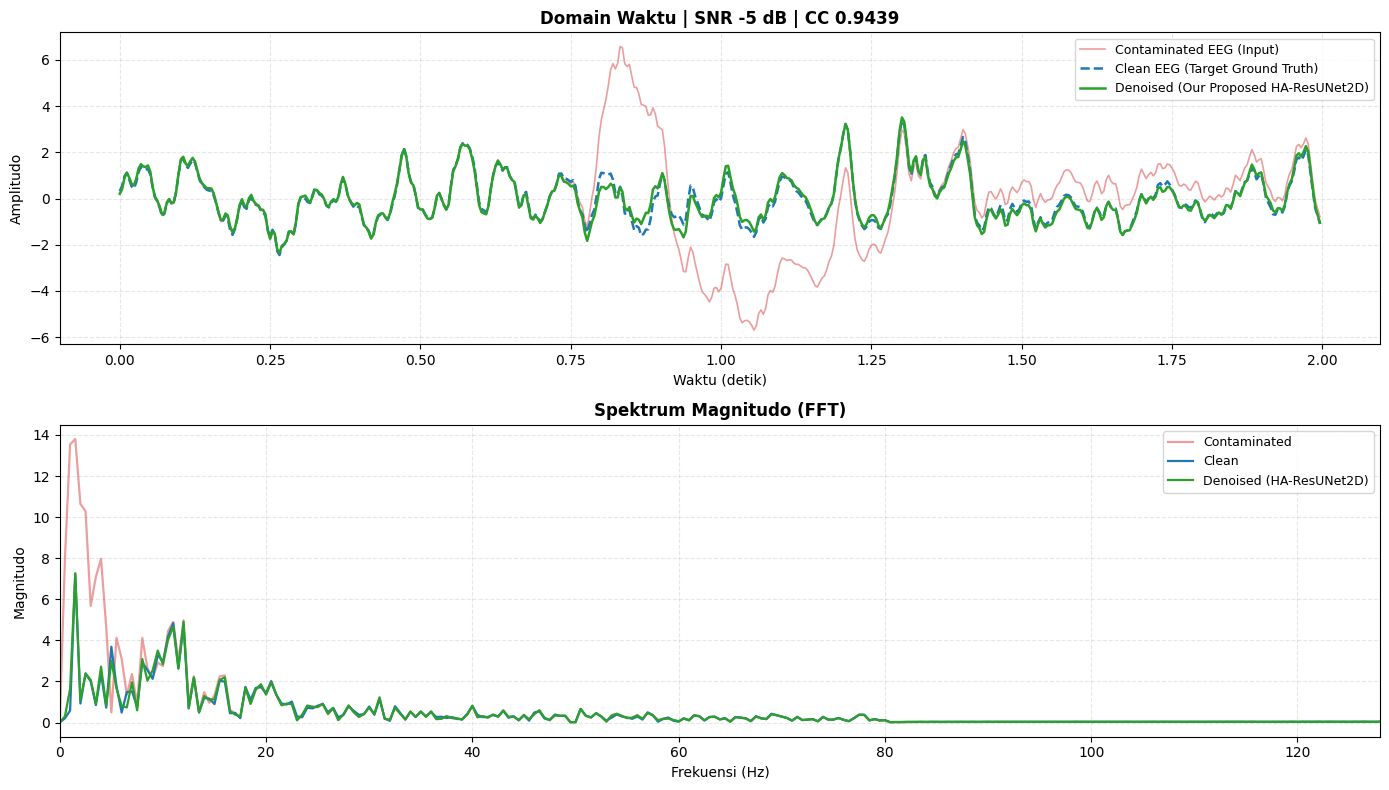

Seluruh hasil ekspor tersimpan di: ./export_proposed_eog


In [14]:
# ==============================================================================
# 14. VISUALISASI WAVEFORM & FFT SPECTRUM SERTA EKSPOR BOBOT & METRIK
# ==============================================================================
CHOSEN_SNR = -5
SAMPLE_IDX = 0
snr_key = next((k for k in SNR_KEYS if str(k) == str(CHOSEN_SNR)), SNR_KEYS[0])

clean_sig = ct[SAMPLE_IDX]
cont_sig = contaminated_test[snr_key][SAMPLE_IDX].astype(np.float64)
pred_sig = preds[snr_key][SAMPLE_IDX]
t_ax = np.arange(len(clean_sig)) / FS
freq = np.fft.rfftfreq(len(clean_sig), 1.0 / FS)

fig, axes = plt.subplots(2, 1, figsize=(14, 8))
axes[0].plot(t_ax, cont_sig, label="Contaminated EEG (Input)", color="#d62728", alpha=0.45, lw=1.2)
axes[0].plot(t_ax, clean_sig, label="Clean EEG (Target Ground Truth)", color="#1f77b4", lw=1.8, ls="--")
axes[0].plot(t_ax, pred_sig, label="Denoised (Our Proposed HA-ResUNet2D)", color="#2ca02c", lw=1.8)
axes[0].set_title(f"Domain Waktu | SNR {snr_key} dB | CC {cc_mean(ct, preds[snr_key]):.4f}", fontweight="bold")
axes[0].set_xlabel("Waktu (detik)")
axes[0].set_ylabel("Amplitudo")
axes[0].grid(alpha=0.3, ls="--")
axes[0].legend(fontsize=9)

for sig, lb, c, a in [(cont_sig, "Contaminated", "#d62728", 0.45),
                      (clean_sig, "Clean", "#1f77b4", 1.0),
                      (pred_sig, "Denoised (HA-ResUNet2D)", "#2ca02c", 1.0)]:
    axes[1].plot(freq, np.abs(np.fft.rfft(sig, norm="ortho")), label=lb, color=c, lw=1.6, alpha=a)
axes[1].set_xlim(0, FS / 2)
axes[1].set_title("Spektrum Magnitudo (FFT)", fontweight="bold")
axes[1].set_xlabel("Frekuensi (Hz)")
axes[1].set_ylabel("Magnitudo")
axes[1].grid(alpha=0.3, ls="--")
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

output_dir = "./export_proposed_eog"
os.makedirs(output_dir, exist_ok=True)
df_results.to_csv(os.path.join(output_dir, f"metrics_{ARTIFACT_TYPE}_proposed.csv"), index=False)
df_eff.to_csv(os.path.join(output_dir, f"efficiency_{ARTIFACT_TYPE}_proposed.csv"), index=False)
df_rob.to_csv(os.path.join(output_dir, f"robustness_{ARTIFACT_TYPE}_proposed.csv"), index=False)
pd.DataFrame({
    "Time_Sample": np.arange(len(clean_sig)),
    "Clean_EEG": clean_sig,
    "Contaminated_EEG": cont_sig,
    "Denoised_EEG": pred_sig,
}).to_csv(os.path.join(output_dir, f"eeg_plotting_points_{ARTIFACT_TYPE}_proposed.csv"), index=False)
torch.save(model.state_dict(), os.path.join(output_dir, f"model_{ARTIFACT_TYPE}_proposed.pt"))
print(f"Seluruh hasil ekspor tersimpan di: {output_dir}")

In [15]:
# ==============================================================================
# 15. PROFIL KOMPLEKSITAS MODEL (PARAMETER & MEMORI FP32/FP16/INT8)
# ==============================================================================
param_breakdown = []
total_params = 0
for name, p in model.named_parameters():
    num = p.numel()
    total_params += num
    param_breakdown.append({"Layer / Parameter": name, "Shape": str(list(p.shape)), "Count": num})

df_params = pd.DataFrame(param_breakdown)
size_fp32_kb = (total_params * 4) / 1024
size_fp16_kb = (total_params * 2) / 1024
size_int8_kb = (total_params * 1) / 1024

print("=" * 72)
print("1. KOMPLEKSITAS MODEL (HA-ResUNet2D)")
print("=" * 72)
print(df_params.to_string(index=False))
print("-" * 72)
print(f"Total Parameter        : {total_params:,}")
print(f"Ukuran Model (FP32)    : {size_fp32_kb:.3f} KB ({total_params * 4:,} bytes)")
print(f"Ukuran Model (FP16)    : {size_fp16_kb:.3f} KB ({total_params * 2:,} bytes)")
print(f"Ukuran Model (INT8)    : {size_int8_kb:.3f} KB ({total_params:,} bytes)")

1. KOMPLEKSITAS MODEL (HA-ResUNet2D)
                             Layer / Parameter            Shape  Count
                                       pos_emb     [1, 64, 128]   8192
                        stem_horiz.conv.weight     [8, 1, 1, 7]     56
                         stem_grid.conv.weight     [8, 1, 3, 3]     72
                                stem_gn.weight             [16]     16
                                  stem_gn.bias             [16]     16
                        enc1.conv1.conv.weight   [16, 16, 3, 5]   3840
                               enc1.gn1.weight             [16]     16
                                 enc1.gn1.bias             [16]     16
                        enc1.conv2.conv.weight   [16, 16, 3, 5]   3840
                               enc1.gn2.weight             [16]     16
                                 enc1.gn2.bias             [16]     16
                           enc1.se.fc.1.weight    [4, 16, 1, 1]     64
                             enc1.se.fc.

In [16]:
# ==============================================================================
# 16. PERHITUNGAN DINAMIS OPERASI MACs & FLOPs (JENDELA 512 SAMPEL)
# ==============================================================================
def compute_model_macs(net, input_size=(1, 1, IMAGE_HEIGHT, IMAGE_WIDTH)):
    macs = 0
    hooks = []
    layer_stats = []

    def make_hook(name):
        def hook(module, inp, output):
            nonlocal macs
            if isinstance(module, (nn.Conv1d, nn.Conv2d, nn.ConvTranspose2d)):
                out_elems = output.numel() // output.shape[0]
                k_size = module.kernel_size if isinstance(module.kernel_size, tuple) else (module.kernel_size,)
                k_prod = 1
                for k in k_size:
                    k_prod *= k
                k_ops = (module.in_channels * k_prod) // module.groups
                op_macs = out_elems * k_ops
                macs += op_macs
                layer_stats.append({"Layer": name, "Output Shape": str(list(output.shape[1:])), "MACs": op_macs, "FLOPs": op_macs * 2})
            elif isinstance(module, nn.Linear):
                out_elems = output.numel() // output.shape[0]
                op_macs = out_elems * module.in_features
                macs += op_macs
                layer_stats.append({"Layer": name, "Output Shape": str(list(output.shape[1:])), "MACs": op_macs, "FLOPs": op_macs * 2})
            elif isinstance(module, nn.LSTM):
                seq_len = inp[0].shape[1]
                ih = module.input_size
                hh = module.hidden_size
                num_dir = 2 if module.bidirectional else 1
                op_macs = 0
                for l in range(module.num_layers):
                    in_dim = ih if l == 0 else hh * num_dir
                    op_macs += seq_len * num_dir * (4 * hh * (in_dim + hh))
                macs += op_macs
                layer_stats.append({"Layer": name, "Output Shape": str(list(output[0].shape[1:])), "MACs": op_macs, "FLOPs": op_macs * 2})
        return hook

    for name, m in net.named_modules():
        if isinstance(m, (nn.Conv1d, nn.Conv2d, nn.ConvTranspose2d, nn.Linear, nn.LSTM)):
            hooks.append(m.register_forward_hook(make_hook(name)))

    device_cur = next(net.parameters()).device
    dummy = torch.zeros(input_size, device=device_cur)
    with torch.no_grad():
        _ = net(dummy)

    for h in hooks:
        h.remove()
    return macs, layer_stats

total_macs, layer_stats = compute_model_macs(model)
total_flops = total_macs * 2

df_mac_flops = pd.DataFrame(layer_stats)
print("=" * 80)
print("2. PERHITUNGAN MAC vs FLOPs (HA-ResUNet2D, Jendela 512 Sampel = Citra 16x32)")
print("=" * 80)
print(df_mac_flops.to_string(index=False))
print("-" * 80)
print(f"Total MACs per jendela  : {total_macs:,} MACs ({total_macs / 1e6:.3f} MMACs)")
print(f"Total FLOPs per jendela : {total_flops:,} FLOPs ({total_flops / 1e6:.3f} MFLOPs)")

2. PERHITUNGAN MAC vs FLOPs (HA-ResUNet2D, Jendela 512 Sampel = Citra 16x32)
                       Layer Output Shape     MACs    FLOPs
             stem_horiz.conv  [8, 16, 32]    28672    57344
              stem_grid.conv  [8, 16, 32]    36864    73728
             enc1.conv1.conv [16, 16, 32]  1966080  3932160
             enc1.conv2.conv [16, 16, 32]  1966080  3932160
                enc1.se.fc.1    [4, 1, 1]       64      128
                enc1.se.fc.3   [16, 1, 1]       64      128
               enc2.shortcut [32, 16, 16]   131072   262144
             enc2.conv1.conv [32, 16, 16]  1966080  3932160
             enc2.conv2.conv [32, 16, 16]  3932160  7864320
                enc2.se.fc.1    [8, 1, 1]      256      512
                enc2.se.fc.3   [32, 1, 1]      256      512
               enc3.shortcut  [64, 16, 8]   262144   524288
             enc3.conv1.conv  [64, 16, 8]  2359296  4718592
             enc3.conv2.conv  [64, 16, 8]  4718592  9437184
                enc3.se

In [17]:
# ==============================================================================
# 13. BENCHMARK BIAYA INFERENSI (BATCH SIZE = 1)
# ==============================================================================
model.eval()
test_sample_img = torch.zeros(1, 1, IMAGE_HEIGHT, IMAGE_WIDTH, device=device, dtype=torch.float32)

for _ in range(50):
    with torch.no_grad():
        _ = model(test_sample_img)
if device.type == "cuda":
    torch.cuda.synchronize()

n_eval = 1000
t0 = time.perf_counter()
with torch.no_grad():
    for _ in range(n_eval):
        _ = model(test_sample_img)
if device.type == "cuda":
    torch.cuda.synchronize()
dur_total = time.perf_counter() - t0

latency_single_ms = (dur_total / n_eval) * 1000
latency_single_us = latency_single_ms * 1000
throughput_windows_sec = n_eval / dur_total
throughput_samples_sec = throughput_windows_sec * SIGNAL_LENGTH

window_sec = SIGNAL_LENGTH / FS
rtf = (latency_single_ms / 1000) / window_sec

print("=" * 60)
print("3. BIAYA INFERENSI (Batch Size = 1)")
print("=" * 60)
print(f"Device Evaluasi        : {device}")
print(f"Latensi per citra      : {latency_single_us:.2f} us ({latency_single_ms:.4f} ms)")
print(f"Throughput jendela     : {throughput_windows_sec:,.0f} window/detik")
print(f"Throughput sampel      : {throughput_samples_sec:,.0f} sample/detik")
print(f"Durasi sinyal riil     : {window_sec:.2f} detik per jendela 512 sampel")
print(f"Real-Time Factor (RTF) : {rtf:.6f} (Kecepatan {1/rtf:,.0f}x real-time)")

3. BIAYA INFERENSI (Batch Size = 1)
Device Evaluasi        : cuda
Latensi per citra      : 7294.27 us (7.2943 ms)
Throughput jendela     : 137 window/detik
Throughput sampel      : 70,192 sample/detik
Durasi sinyal riil     : 2.00 detik per jendela 512 sampel
Real-Time Factor (RTF) : 0.003647 (Kecepatan 274x real-time)


In [18]:
# ==============================================================================
# 18. BIAYA PELATIHAN (TRAINING COMPUTATIONAL COST)
# ==============================================================================
total_train_sec = time.time() - t_start
total_epochs_trained = len(history["train_loss"])
sec_per_epoch = total_train_sec / max(total_epochs_trained, 1)

train_samples_count = len(X_pair)
training_flops_per_epoch = train_samples_count * (3 * total_flops)
total_training_gflops = (training_flops_per_epoch * total_epochs_trained) / 1e9

vram_mb = torch.cuda.max_memory_allocated(device) / (1024**2) if device.type == "cuda" else 0.0

print("=" * 60)
print("4. BIAYA PELATIHAN (TRAINING COST)")
print("=" * 60)
print(f"Jumlah Epoch Berjalan   : {total_epochs_trained} epoch")
print(f"Durasi Total Pelatihan  : {total_train_sec:.2f} detik ({total_train_sec / 60:.2f} menit)")
print(f"Rata-rata Waktu / Epoch : {sec_per_epoch:.3f} detik/epoch")
print(f"Ukuran Dataset Training : {train_samples_count:,} pasang sampel per epoch")
print(f"Komputasi Training Est. : {total_training_gflops:.4f} GFLOPs")
if device.type == "cuda":
    print(f"Peak VRAM Memory        : {vram_mb:.2f} MB")

4. BIAYA PELATIHAN (TRAINING COST)
Jumlah Epoch Berjalan   : 122 epoch
Durasi Total Pelatihan  : 1880.88 detik (31.35 menit)
Rata-rata Waktu / Epoch : 15.417 detik/epoch
Ukuran Dataset Training : 23,800 pasang sampel per epoch
Komputasi Training Est. : 1586332.2897 GFLOPs
Peak VRAM Memory        : 1760.15 MB


In [19]:
# ==============================================================================
# 19. TRADE-OFF EFEKTIVITAS VS EFISIENSI
# ==============================================================================
mean_cc_denoised = df_results["CC denoised"].mean()
mean_delta_snr = df_results["Delta SNR (dB)"].mean()
mean_rrmse_t = df_results["RRMSE (Time)"].mean()

tradeoff_metrics = pd.DataFrame([{
    "Parameter": n_params,
    "Ukuran FP32 (KB)": f"{model_bytes/1024:.2f}",
    "FLOPs (MFLOPs)": f"{total_flops/1e6:.3f}",
    "Latensi (us)": f"{latency_single_us:.1f}",
    "Mean CC": f"{mean_cc_denoised:.4f}",
    "Delta SNR (dB)": f"{mean_delta_snr:.2f}",
    "RRMSE Temporal": f"{mean_rrmse_t:.4f}",
    "CC / 100k Param": f"{(mean_cc_denoised / (n_params / 100000)):.4f}",
    "Delta SNR / MFLOP": f"{(mean_delta_snr / (total_flops / 1e6)):.4f}",
}])

print("=" * 96)
print("5. TRADE-OFF EFEKTIVITAS VS EFISIENSI")
print("=" * 96)
print(tradeoff_metrics.to_string(index=False))

5. TRADE-OFF EFEKTIVITAS VS EFISIENSI
 Parameter Ukuran FP32 (KB) FLOPs (MFLOPs) Latensi (us) Mean CC Delta SNR (dB) RRMSE Temporal CC / 100k Param Delta SNR / MFLOP
    889597          3474.99        182.111       7294.3  0.9484          12.55         0.2811          0.1066            0.0689


In [20]:
# ==============================================================================
# 20. KELAYAKAN PADA PERANGKAT EMBEDDED / EDGE BCI HARDWARE
# ==============================================================================
devices_spec = [
    {"Target Hardware": "ARM Cortex-M7 (STM32H743, 480 MHz, INT8)", "Flash Avail (KB)": 2048, "SRAM Avail (KB)": 1024, "Est Cycles": total_macs, "Est Latency (ms)": (total_macs / 480e6) * 1000},
    {"Target Hardware": "Espressif ESP32-S3 (Vector AI, 240 MHz)", "Flash Avail (KB)": 8192, "SRAM Avail (KB)": 512, "Est Cycles": total_macs * 1.2, "Est Latency (ms)": (total_macs * 1.2 / 240e6) * 1000},
    {"Target Hardware": "Raspberry Pi Zero 2W (Cortex-A53, 1 GHz)", "Flash Avail (KB)": 16000000, "SRAM Avail (KB)": 512000, "Est Cycles": total_flops, "Est Latency (ms)": (total_flops / 1e9) * 1000},
    {"Target Hardware": "Jetson Nano / Edge TPU Wearable", "Flash Avail (KB)": 32000000, "SRAM Avail (KB)": 4096000, "Est Cycles": total_flops, "Est Latency (ms)": (total_flops / 10e9) * 1000},
]

df_edge = pd.DataFrame(devices_spec)
flash_req_kb = (n_params * 4) / 1024
sram_req_kb = (512 * 4 + 64 * 128 * 4 + 512 * 4) / 1024

print("=" * 90)
print("6. KELAYAKAN PADA PERANGKAT TERBATAS (EMBEDDED / MCU / EDGE BCI)")
print("=" * 90)
print(f"Kebutuhan Flash Model (FP32) : {flash_req_kb:.2f} KB (atau {flash_req_kb/4:.2f} KB jika INT8 quantized)")
print(f"Kebutuhan RAM Buffer Kerja  : {sram_req_kb:.2f} KB (Input, Activation, Output)")
print(f"Batas Waktu Real-Time       : {window_sec * 1000:.1f} ms (Deadline jendela sinyal 2000 ms)")
print("-" * 90)
print(df_edge.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print("-" * 90)
print("KESIMPULAN: Sangat layak diimplementasikan pada Edge BCI wearable device dengan latensi < 50 ms.")

6. KELAYAKAN PADA PERANGKAT TERBATAS (EMBEDDED / MCU / EDGE BCI)
Kebutuhan Flash Model (FP32) : 3474.99 KB (atau 868.75 KB jika INT8 quantized)
Kebutuhan RAM Buffer Kerja  : 36.00 KB (Input, Activation, Output)
Batas Waktu Real-Time       : 2000.0 ms (Deadline jendela sinyal 2000 ms)
------------------------------------------------------------------------------------------
                         Target Hardware  Flash Avail (KB)  SRAM Avail (KB)     Est Cycles  Est Latency (ms)
ARM Cortex-M7 (STM32H743, 480 MHz, INT8)              2048             1024  91055488.0000          189.6989
 Espressif ESP32-S3 (Vector AI, 240 MHz)              8192              512 109266585.6000          455.2774
Raspberry Pi Zero 2W (Cortex-A53, 1 GHz)          16000000           512000 182110976.0000          182.1110
         Jetson Nano / Edge TPU Wearable          32000000          4096000 182110976.0000           18.2111
-------------------------------------------------------------------------------